# Kesit İstatistik — İleri Bayes ve simülasyon

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Eşlenik önseller ve hiyerarşik Bayes

Az gözlemli grubun oranını ortak önselle nasıl güncellerim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Beta sonsallarının genişliği ile örneklem büyüklüğünü eşleştir.

**Yorum sınırı:** Burada üst düzey Beta parametreleri sabittir; onların belirsizliğini öğrenen tam hiyerarşik model değildir.

**Alıştırma:** Önseli Beta(2,18) yerine Beta(1,1) yap; küçük grupta etkiyi açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'k': 1, 'n': 8, 'ham': 0.125, 'sonsal': np.float64(0.10714285714285714), 'CI95': [0.02352745438085398, 0.24289834684562717]}
{'k': 10, 'n': 80, 'ham': 0.125, 'sonsal': np.float64(0.12), 'CI95': [0.06422779037888428, 0.19011643481938723]}
{'k': 30, 'n': 200, 'ham': 0.15, 'sonsal': np.float64(0.14545454545454545), 'CI95': [0.10214110448001647, 0.19486687037410083]}


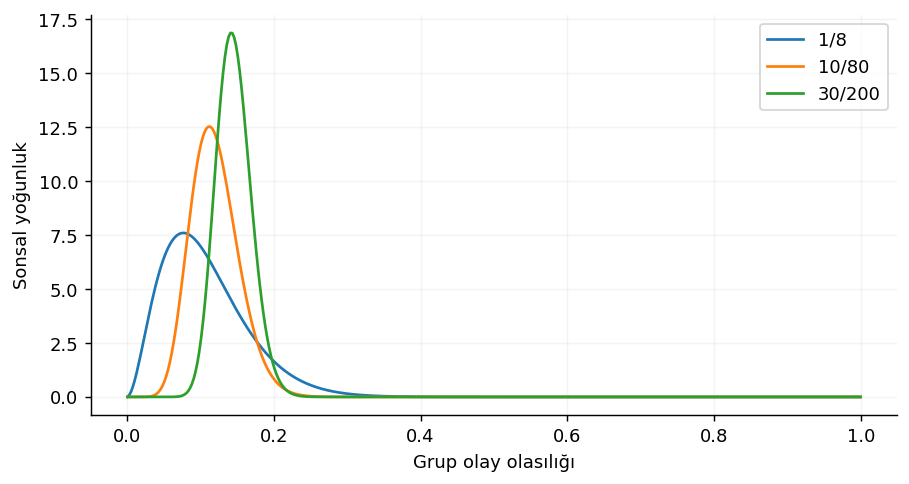

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

a,b=2,18;groups=[(1,8),(10,80),(30,200)];p=np.linspace(.001,.999,400)
for k,n in groups:
 post=stats.beta(a+k,b+n-k);print({'k':k,'n':n,'ham':k/n,'sonsal':post.mean(),'CI95':post.ppf([.025,.975]).tolist()});plt.plot(p,post.pdf(p),label=f'{k}/{n}')
plt.xlabel('Grup olay olasılığı');plt.ylabel('Sonsal yoğunluk');plt.legend()

## MCMC ve yakınsama tanıları

Yüksek kabul oranı iyi karışma anlamına gelir mi?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** İzleri ve klasik split R-hat değerini adım boyuna göre karşılaştır.

**Yorum sınırı:** Random-walk öğretim uygulaması modern rank-normalize R-hat ve HMC tanılarının yerine geçmez.

**Alıştırma:** step=.12 yerine .005 kullan; kabul ve zincirler arası farkı birlikte yorumla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'kabul': 0.7175, 'klasik_split_Rhat': np.float64(1.00263877554605), 'cekim_ortalama': np.float64(0.3536931887772823), 'analitik': 0.35714285714285715}


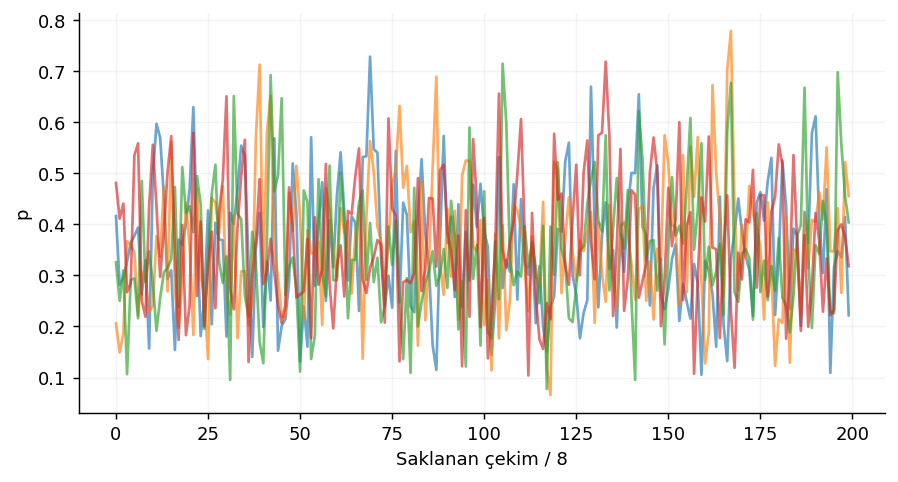

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

a,b,step=5,9,.12;chains=[];accepted=0
for start in [.1,.35,.65,.9]:
 z=start;out=[]
 for i in range(2400):
  proposal=z+rng.normal(0,step)
  if 0<proposal<1 and np.log(rng.uniform())<stats.beta.logpdf(proposal,a,b)-stats.beta.logpdf(z,a,b):z=proposal;accepted+=1
  if i>=800:out.append(z)
 chains.append(out)
c=np.array(chains);split=c.reshape(8,800);W=split.var(axis=1,ddof=1).mean();B=800*split.mean(axis=1).var(ddof=1);rhat=np.sqrt(((799/800)*W+B/800)/W)
print({'kabul':accepted/9600,'klasik_split_Rhat':rhat,'cekim_ortalama':c.mean(),'analitik':a/(a+b)})
plt.plot(c.T[::8],alpha=.65);plt.xlabel('Saklanan çekim / 8');plt.ylabel('p')

## Sonsal öngörü kontrolü

Model gözlenen hata sayısını yeniden üretebiliyor mu?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Gözlenen istatistiği sonsal öngörü histogramıyla karşılaştır.

**Yorum sınırı:** Sonsal öngörü kontrolü model uygunluğuna bakar; kullanılan veriden bağımsız doğrulama değildir.

**Alıştırma:** n=100,k=12 değerini değiştir; öngörü ile parametre aralığını ayır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'yeni_sayim_ortalama': np.float64(11.66625), 'ongoru_95': [4.0, 21.0], 'gozlenen': 12, 'parametre_95': [0.0667689009431097, 0.17832741200793395]}


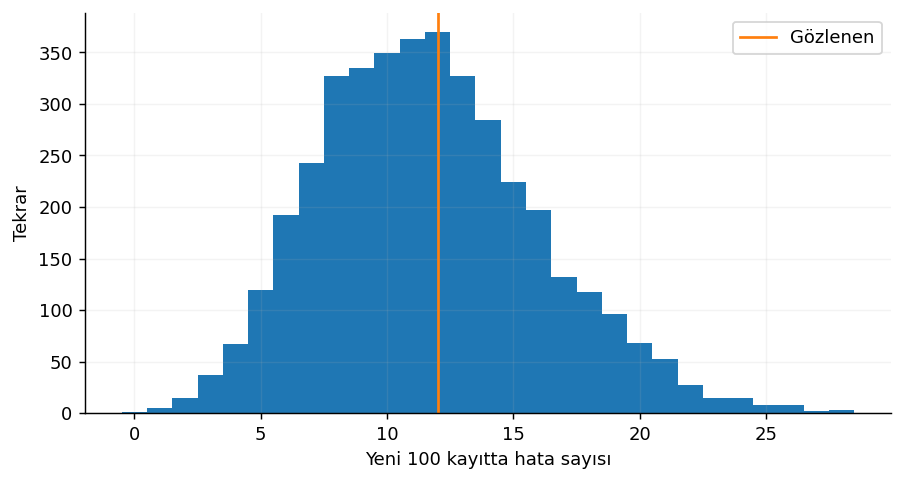

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

k,n=12,100;p=rng.beta(2+k,18+n-k,4000);rep=rng.binomial(n,p);print({'yeni_sayim_ortalama':rep.mean(),'ongoru_95':np.quantile(rep,[.025,.975]).tolist(),'gozlenen':k,'parametre_95':np.quantile(p,[.025,.975]).tolist()})
plt.hist(rep,bins=np.arange(rep.max()+2)-.5);plt.axvline(k,c='tab:orange',label='Gözlenen');plt.xlabel('Yeni 100 kayıtta hata sayısı');plt.ylabel('Tekrar');plt.legend()

## Duyarlılık, karar eşiği ve Bayes faktörü

Önsel ve hata maliyeti kararı nasıl değiştirir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Farklı önsellerde sonsal ve BF10 değerini karşılaştır.

**Yorum sınırı:** Bayes faktörü belirtilen nokta H0 ile Beta alternatifini karşılaştırır; önsele duyarlıdır.

**Alıştırma:** H0 oranını .1’den .2’ye değiştir; maliyet eşiğini ayrı değerlendir.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


  Beta_onsel  P_p_buyuk_H0      BF10
0        1,1      0.994877  1.824554
1       2,18      0.985537  3.935736
2      10,90      0.958859  3.016920
Pozitif karar eşiği: 0.16666666666666666


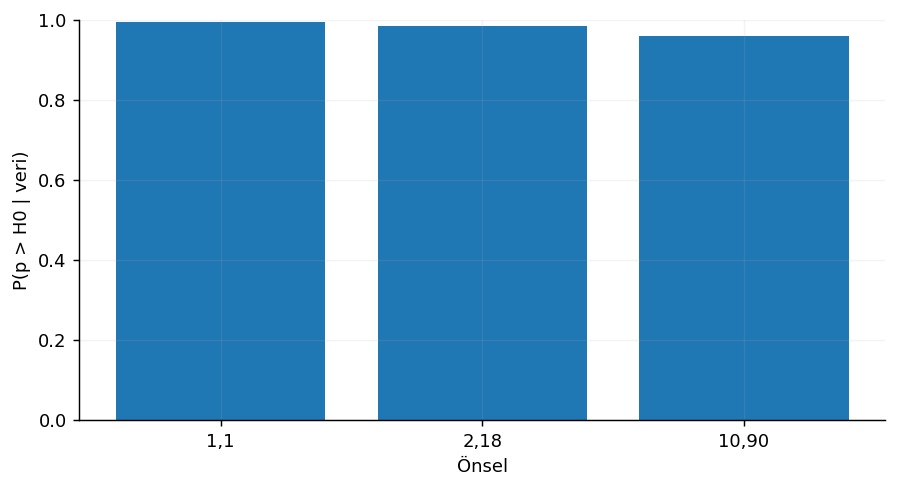

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

k,n,p0=18,100,.1;rows=[]
for a,b in [(1,1),(2,18),(10,90)]:
 logBF=special.betaln(a+k,b+n-k)-special.betaln(a,b)-k*np.log(p0)-(n-k)*np.log1p(-p0);prob=stats.beta.sf(p0,a+k,b+n-k);rows.append([f'{a},{b}',prob,np.exp(logBF)])
print(pd.DataFrame(rows,columns=['Beta_onsel','P_p_buyuk_H0','BF10']));C_FP,C_FN=2,10;print('Pozitif karar eşiği:',C_FP/(C_FP+C_FN))
plt.bar([r[0] for r in rows],[r[1] for r in rows]);plt.ylim(0,1);plt.xlabel('Önsel');plt.ylabel('P(p > H0 | veri)')